# Issue #314 — CORE/TAIL soft-MoE and explicit coverage

This notebook reads the immutable result package. It shows the chronological
freeze, exact 2023 baseline anchor, one-shot 2024 capital paths, matched factor
resets and near-miss attribution. Beijing's 0.65 factor is applied once per
complete winning N-fold ticket.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / 'results' / 'issue-314').is_dir())
OUTPUT = ROOT / 'results' / 'issue-314'
freeze = json.loads((OUTPUT / 'freeze_receipt.json').read_text())
decision = json.loads((OUTPUT / 'decision.json').read_text())
display(freeze)
display(decision)

{'contract': 'BJ-UNIFIED-CORE-TAIL-MOE-001/v1',
 'selected_model_family': 'RIDGE',
 'selected_tail_fraction': 0.05,
 'validation_pass': False,
 'guarded_source': 'PORTABLE_N7_K512_WOR',
 'validation_control': 'EXACT_ISSUE312_FIXED_N7_K512_WOR',
 'terminal_control': 'PORTABLE_N7_K512_WOR',
 'terminal_control_limitation': 'same N7/K512/WOR exposure and current causal value input; #312 fitted-value identities do not exist for 2024',
 '2024_feature_issues': 66,
 '2024_outcome_columns_opened': [],
 'allocation_sha256': '88211b8fc5616649bac39ea45b12aff7d38e05bece5bbf313ef7b05b6d69637d',
 'model_sha256': '114d65baa0efdaf9169c503a8c82d6f48d7bd2cc9e198a6ae4a45bf830d8a0f7',
 'independent_unit': 'BEIJING_ISSUE',
 'nuisance_seeds_nested': [312101,
  312102,
  312103,
  312104,
  312105,
  312106,
  312107,
  312108,
  312109,
  312110,
  312111,
  312112,
  312113,
  312114,
  312115,
  312116,
  312117,
  312118,
  312119,
  312120,
  312121,
  312122,
  312123,
  312124,
  312125,
  312126,
  31

{'issue': 314,
 'decision': {'verdict': 'STRUCTURAL_SIGNAL',
  'promotable': False,
  'guarded_source': 'PORTABLE_N7_K512_WOR',
  'validation_pass': False,
  'terminal_issues': 66,
  'guarded_terminal_capital_cny': 81882.32251719973,
  'raw_learned_terminal_capital_cny': 34373.99223376185,
  'fixed_n7_terminal_capital_cny': 81882.32251719973,
  'paired_seed_median_lift_raw_vs_fixed_cny': -45972.6079137097,
  'raw_learned_median_stake_cny': 270336.0,
  'fixed_n7_median_stake_cny': 67584.0,
  'lower_exposure_explanation': False,
  'maximum_coverage_depth': 2,
  'payout_factor': 0.65,
  'payout_application': 'ONCE_PER_WINNING_COMPLETE_TICKET',
  'unlock_issue_210': False}}

## Causal support and expert library

In [2]:
support = pd.read_csv(OUTPUT / 'support_receipt.csv')
experts = pd.read_csv(OUTPUT / 'expert_registry.csv')
display(support)
display(experts[['name','sleeve','n','selector','outcome_direction',
                 'generator','protection','protected_leg_count']])

,issue_year,experiment_role,issues,minimum_matches,median_matches,maximum_matches
0,2019,train,47,23,302.0,678
1,2020,train,30,11,220.0,571
2,2021,train,49,13,322.0,631
3,2022,screen,53,16,294.0,567
4,2023,validation,48,22,337.5,495
5,2024,terminal,66,35,285.5,523


,name,sleeve,n,selector,outcome_direction,generator,protection,protected_leg_count
0,CORE_N7_MARKET_WOR,CORE,7,GLOBAL,MARKET,WOR,NONE,0
1,CORE_N7_VALUE_WOR,CORE,7,VALUE,VALUE,WOR,NONE,0
2,CORE_N7_VALUE_WR,CORE,7,VALUE,VALUE,WR,NONE,0
3,CORE_N7_SELECTIVE,CORE,7,HYBRID,VALUE,WOR,UNCERTAINTY,1
4,TAIL_N8_VALUE_WOR,TAIL,8,VALUE,VALUE,WOR,NONE,0
5,TAIL_N9_DIVERGENCE,TAIL,9,DIVERGENCE,DIVERGENCE,WOR,NONE,0
6,TAIL_N10_VALUE_WR,TAIL,10,VALUE,VALUE,WR,NONE,0
7,TAIL_N7_DIVERGENCE_PROTECTED,TAIL,7,DIVERGENCE,DIVERGENCE,WOR,DIVERGENCE,2


## 2022 screen and model-unseen 2023 validation

In [3]:
screen = pd.read_csv(OUTPUT / 'screening_2022.csv')
validation = pd.read_csv(OUTPUT / 'validation_summary_2023.csv')
display(screen[['model_family','tail_fraction','median_terminal_capital_cny',
                'median_stake_cny','median_turnover_roi']])
display(validation.sort_values('median_terminal_capital_cny', ascending=False))

,model_family,tail_fraction,median_terminal_capital_cny,median_stake_cny,median_turnover_roi
0,RIDGE,0.05,99256.971964,6784.0,-0.109527
1,RIDGE,0.15,99122.386493,6784.0,-0.129365
2,RIDGE,0.10,98894.319468,6784.0,-0.162984
3,MLP,0.05,69589.683564,129792.0,-0.234300
4,MLP,0.10,65623.537813,133760.0,-0.257001
5,MLP,0.15,63729.401751,133760.0,-0.271162
6,HGB,0.05,40933.213604,217088.0,-0.272087
7,HGB,0.10,39872.903837,217088.0,-0.276971
8,HGB,0.15,37027.290944,217088.0,-0.290079


,condition,nuisance_seeds,issues,median_terminal_capital_cny,median_stake_cny,median_turnover_roi,median_max_drawdown_cny,median_ex_largest_pnl_cny,median_positive_issue_rate,median_longest_losing_issues,...,median_worst_10_pnl_cny,median_worst_20_pnl_cny,median_time_underwater_issues,median_maximum_completed_recovery_issues,median_open_terminal_underwater_issues,median_longest_no_payout_issues,median_any_payout_issue_rate,median_ticket_hit_rate,median_expert_hhi,paired_seed_wins_vs_fixed
2,FIXED_N7_K512_WOR,31,48,87984.267911,49152.0,-0.244461,16745.998890,-19141.389470,0.208333,9.0,...,-9092.061898,-12130.103831,47.0,5.0,38.0,7.0,0.291667,0.000651,1.000000,NaN
3,PORTABLE_N7_K512_WOR,31,48,87894.611513,49152.0,-0.246285,18824.712075,-19785.457293,0.208333,11.0,...,-9599.518269,-14187.425954,47.0,3.0,44.0,9.0,0.250000,0.000529,1.000000,16.0
0,EQUAL_CORE_MIXTURE,31,48,71820.210960,49152.0,-0.573319,28179.789040,-30896.249444,0.145833,12.0,...,-9947.020950,-16110.725761,48.0,0.0,48.0,6.0,0.541667,0.005127,0.250000,1.0
1,FIXED_CORE_TAIL_90_10,31,48,71355.950095,49152.0,-0.582765,28761.785089,-30843.690350,0.145833,14.0,...,-9834.723059,-16239.469682,48.0,0.0,48.0,5.0,0.541667,0.004964,0.205162,1.0
4,RAW_LEARNED_MOE,31,48,-57.777457,196608.0,-0.508920,100057.777457,-107294.507208,0.208333,15.0,...,-39351.402374,-59601.889679,48.0,0.0,48.0,2.0,0.729167,0.005809,0.437300,0.0


## Frozen 2024 allocations and terminal paths

,condition,total_k,issues
0,EQUAL_CORE_MIXTURE,512,66
1,FIXED_CORE_TAIL_90_10,512,66
2,FIXED_EXPOSURE_512_DIAGNOSTIC,512,66
3,GUARDED_PRIMARY,512,66
4,PORTABLE_N7_K512_WOR,512,66
5,RANDOM_PROTECTION_CONTROL,2048,66
6,RAW_LEARNED_MOE,2048,66
7,RESET_CANDIDATE_SELECTOR,2048,66
8,RESET_COVERAGE_PROTECTION,2048,66
9,RESET_GENERATOR,2048,66


,condition,nuisance_seeds,issues,median_terminal_capital_cny,median_stake_cny,median_turnover_roi,median_max_drawdown_cny,median_ex_largest_pnl_cny,median_positive_issue_rate,median_longest_losing_issues,...,median_worst_10_pnl_cny,median_worst_20_pnl_cny,median_time_underwater_issues,median_maximum_completed_recovery_issues,median_open_terminal_underwater_issues,median_longest_no_payout_issues,median_any_payout_issue_rate,median_ticket_hit_rate,median_expert_hhi,paired_seed_wins_vs_fixed
7,RESET_CANDIDATE_SELECTOR,31,66,89179.258761,270336.0,-0.040027,64785.897967,-69742.030791,0.166667,14.0,...,-37277.492877,-52970.369500,65.0,21.0,43.0,5.0,0.636364,0.012052,0.437300,21.0
2,FIXED_EXPOSURE_512_DIAGNOSTIC,31,66,83304.853632,67584.0,-0.247028,21893.670356,-25538.918725,0.166667,14.0,...,-9378.329261,-15093.581566,66.0,0.0,66.0,5.0,0.606061,0.009529,0.437523,15.0
4,PORTABLE_N7_K512_WOR,31,66,81882.322517,67584.0,-0.268076,27301.507403,-27609.382343,0.181818,14.0,...,-10240.000000,-15288.944381,65.0,4.0,61.0,10.0,0.257576,0.000592,1.000000,NaN
3,GUARDED_PRIMARY,31,66,81882.322517,67584.0,-0.268076,27301.507403,-27609.382343,0.181818,14.0,...,-10240.000000,-15288.944381,65.0,4.0,61.0,10.0,0.257576,0.000592,1.000000,0.0
0,EQUAL_CORE_MIXTURE,31,66,74402.893496,67584.0,-0.378745,28842.218538,-33981.624476,0.166667,15.0,...,-9352.017814,-16121.096012,66.0,0.0,66.0,5.0,0.560606,0.007428,0.250000,10.0
1,FIXED_CORE_TAIL_90_10,31,66,71321.243659,67584.0,-0.424342,31122.700657,-36150.155038,0.166667,14.0,...,-9403.579215,-16637.403674,66.0,0.0,66.0,5.0,0.545455,0.006836,0.205162,10.0
12,RESET_OUTCOME_DIRECTION,31,66,40961.188820,270336.0,-0.218390,82713.085373,-95963.731427,0.166667,14.0,...,-36262.191555,-57355.280935,66.0,0.0,66.0,2.0,0.727273,0.009884,0.437300,0.0
5,RANDOM_PROTECTION_CONTROL,31,66,35564.290095,270336.0,-0.238354,85452.535575,-100662.472312,0.151515,14.0,...,-35593.398533,-58407.359056,66.0,0.0,66.0,2.0,0.727273,0.009758,0.437300,0.0
11,RESET_N,31,66,34579.747536,270336.0,-0.241996,85142.769141,-100808.084600,0.151515,14.0,...,-36360.005502,-57941.591649,66.0,0.0,66.0,2.0,0.727273,0.009817,0.437300,0.0
6,RAW_LEARNED_MOE,31,66,34373.992234,270336.0,-0.242757,86134.193810,-101679.385151,0.151515,14.0,...,-36524.359729,-57941.591649,66.0,0.0,66.0,2.0,0.727273,0.009729,0.437300,0.0


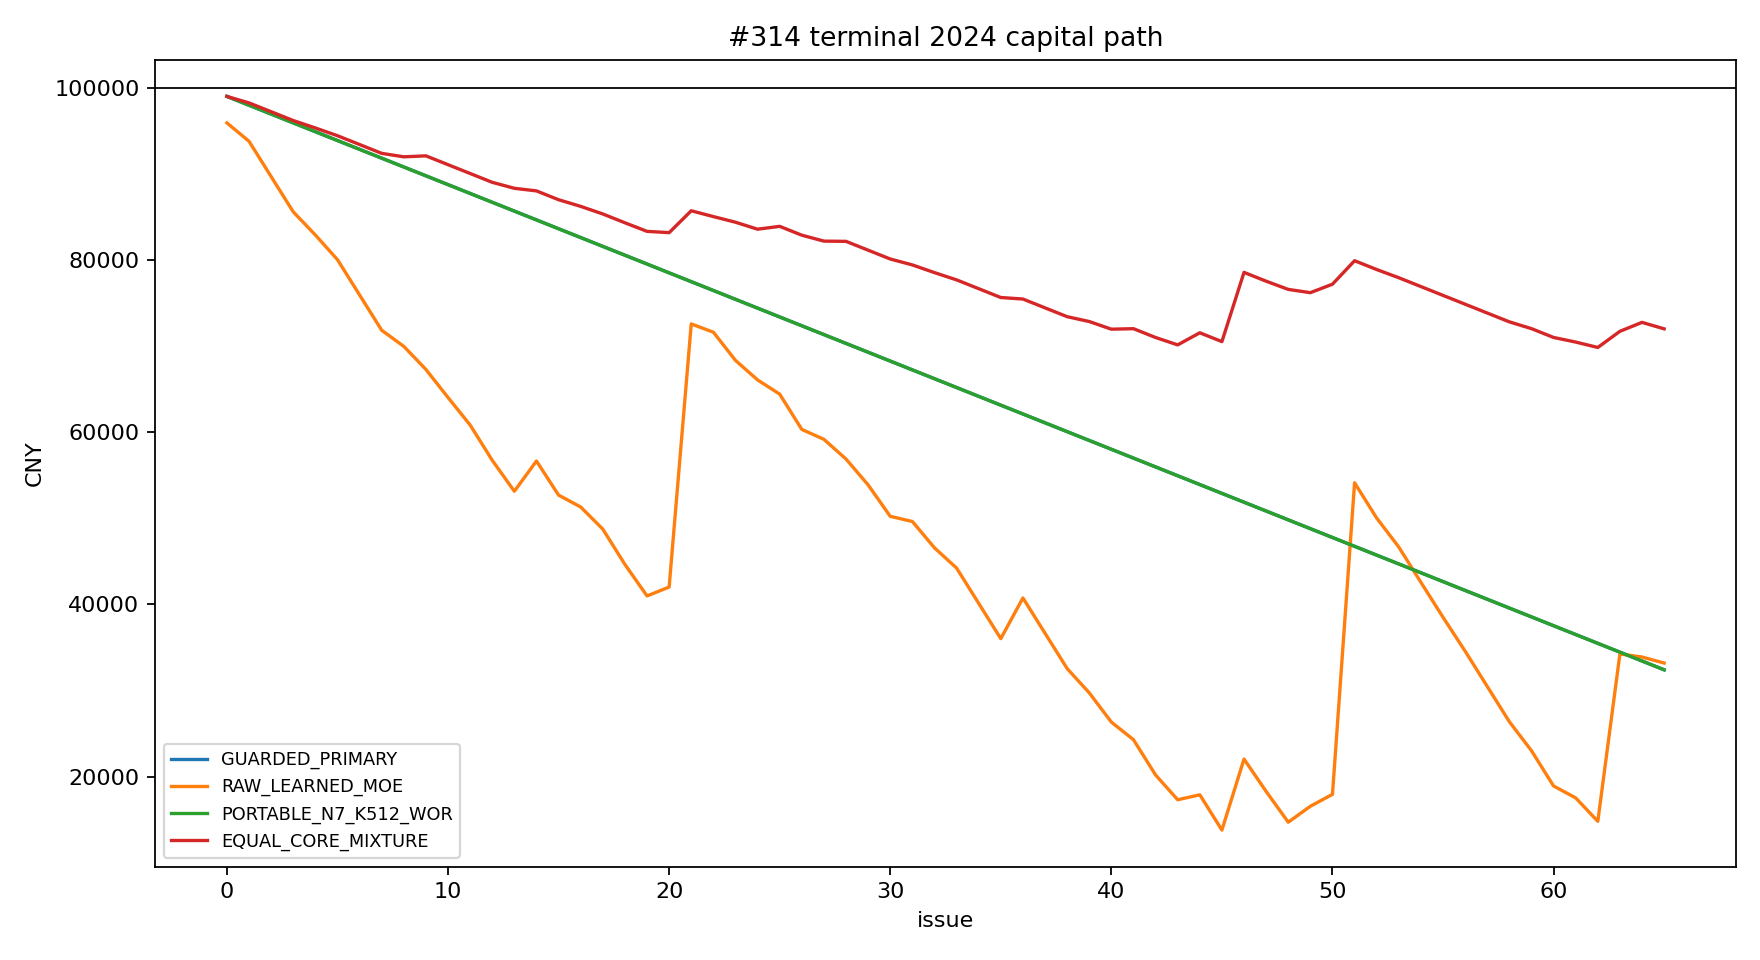

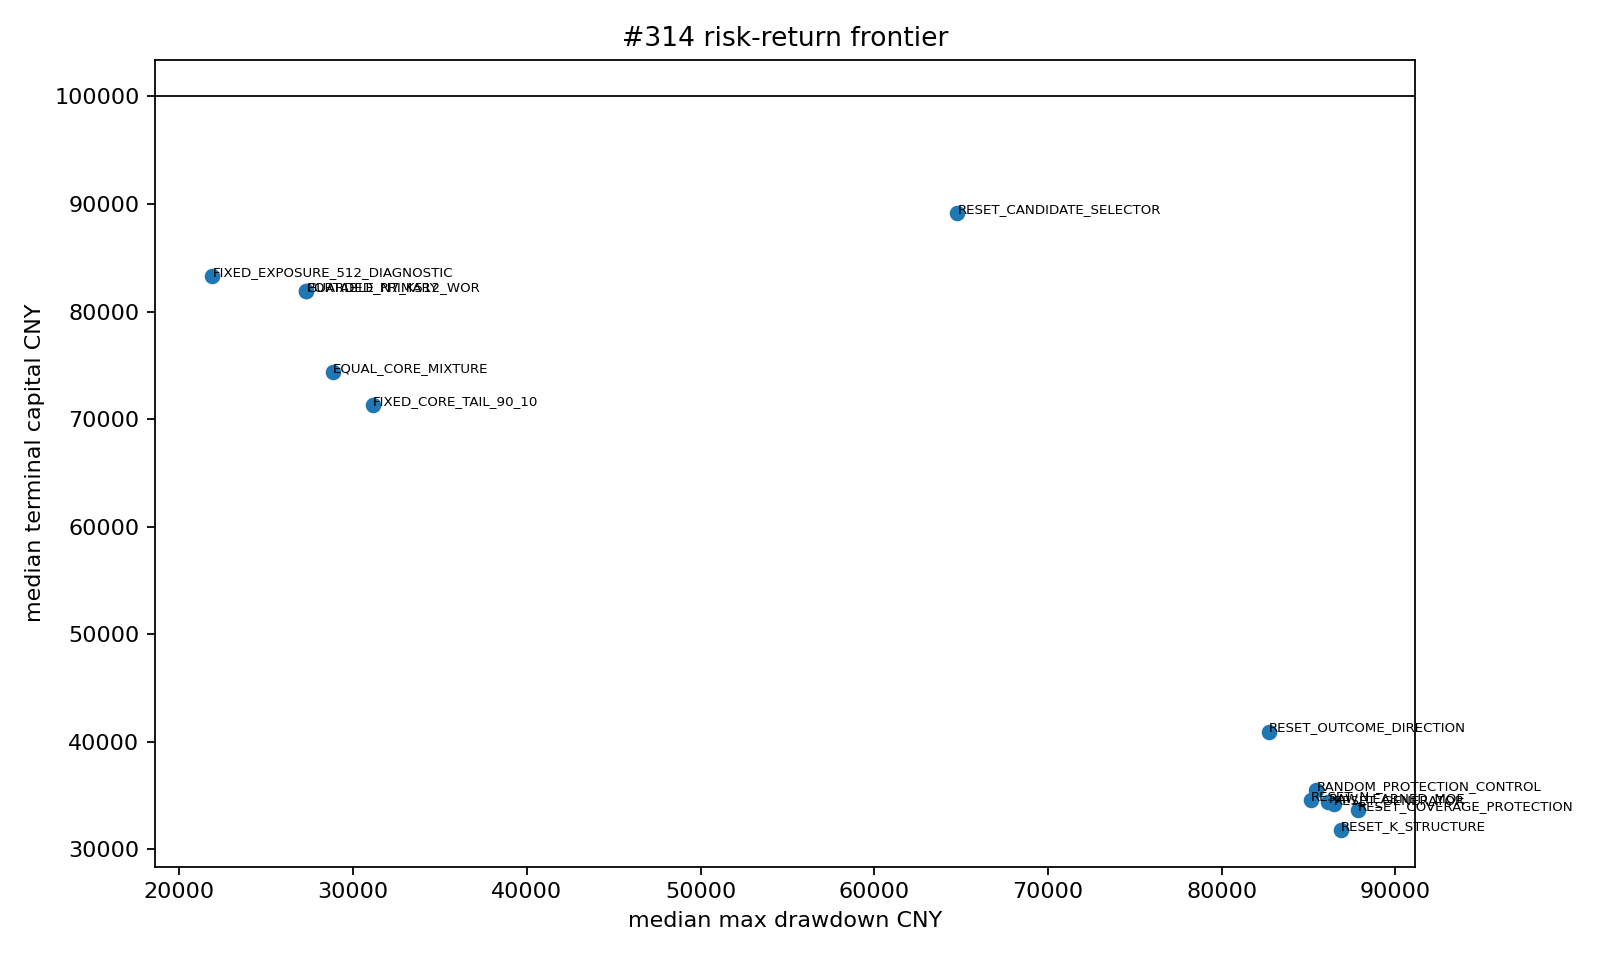

In [4]:
alloc = pd.read_json(OUTPUT / 'frozen_allocations_2024.jsonl', lines=True,
                     dtype={'issue': str})
summary = pd.read_csv(OUTPUT / 'terminal_summary_2024.csv')
display(alloc.groupby(['condition','total_k'], as_index=False)
        .agg(issues=('issue','nunique')))
display(summary.sort_values('median_terminal_capital_cny', ascending=False))
display(Image(filename=str(OUTPUT / 'capital_paths_2024.png')))
display(Image(filename=str(OUTPUT / 'risk_return_frontier_2024.png')))

## Matched factor attribution

In [5]:
factors = pd.read_csv(OUTPUT / 'matched_factor_attribution_2024.csv')
display(factors.sort_values('median_seed_lift_cny', ascending=False))

,reset,median_seed_lift_cny,positive_seed_fraction,matched_issue_seed_rows
3,RESET_K_STRUCTURE,1980.152477,0.580645,2046
1,RESET_COVERAGE_PROTECTION,1048.487854,0.806452,2046
2,RESET_GENERATOR,0.000000,0.483871,2046
4,RESET_N,-668.197107,0.322581,2046
5,RESET_OUTCOME_DIRECTION,-5494.113591,0.000000,2046
0,RESET_CANDIDATE_SELECTOR,-54361.130604,0.000000,2046


## Near-miss reasons and funded protection counterfactual

,condition,miss_one,miss_two,outside_support,finite_sampling,added_stake,added_pnl
0,GUARDED_PRIMARY,7891,45375,1053,97588,15782.0,2.106111e+07
1,PORTABLE_N7_K512_WOR,7891,45375,1053,97588,15782.0,2.106111e+07
2,RAW_LEARNED_MOE,255095,728431,1701862,10095,510190.0,8.952045e+07


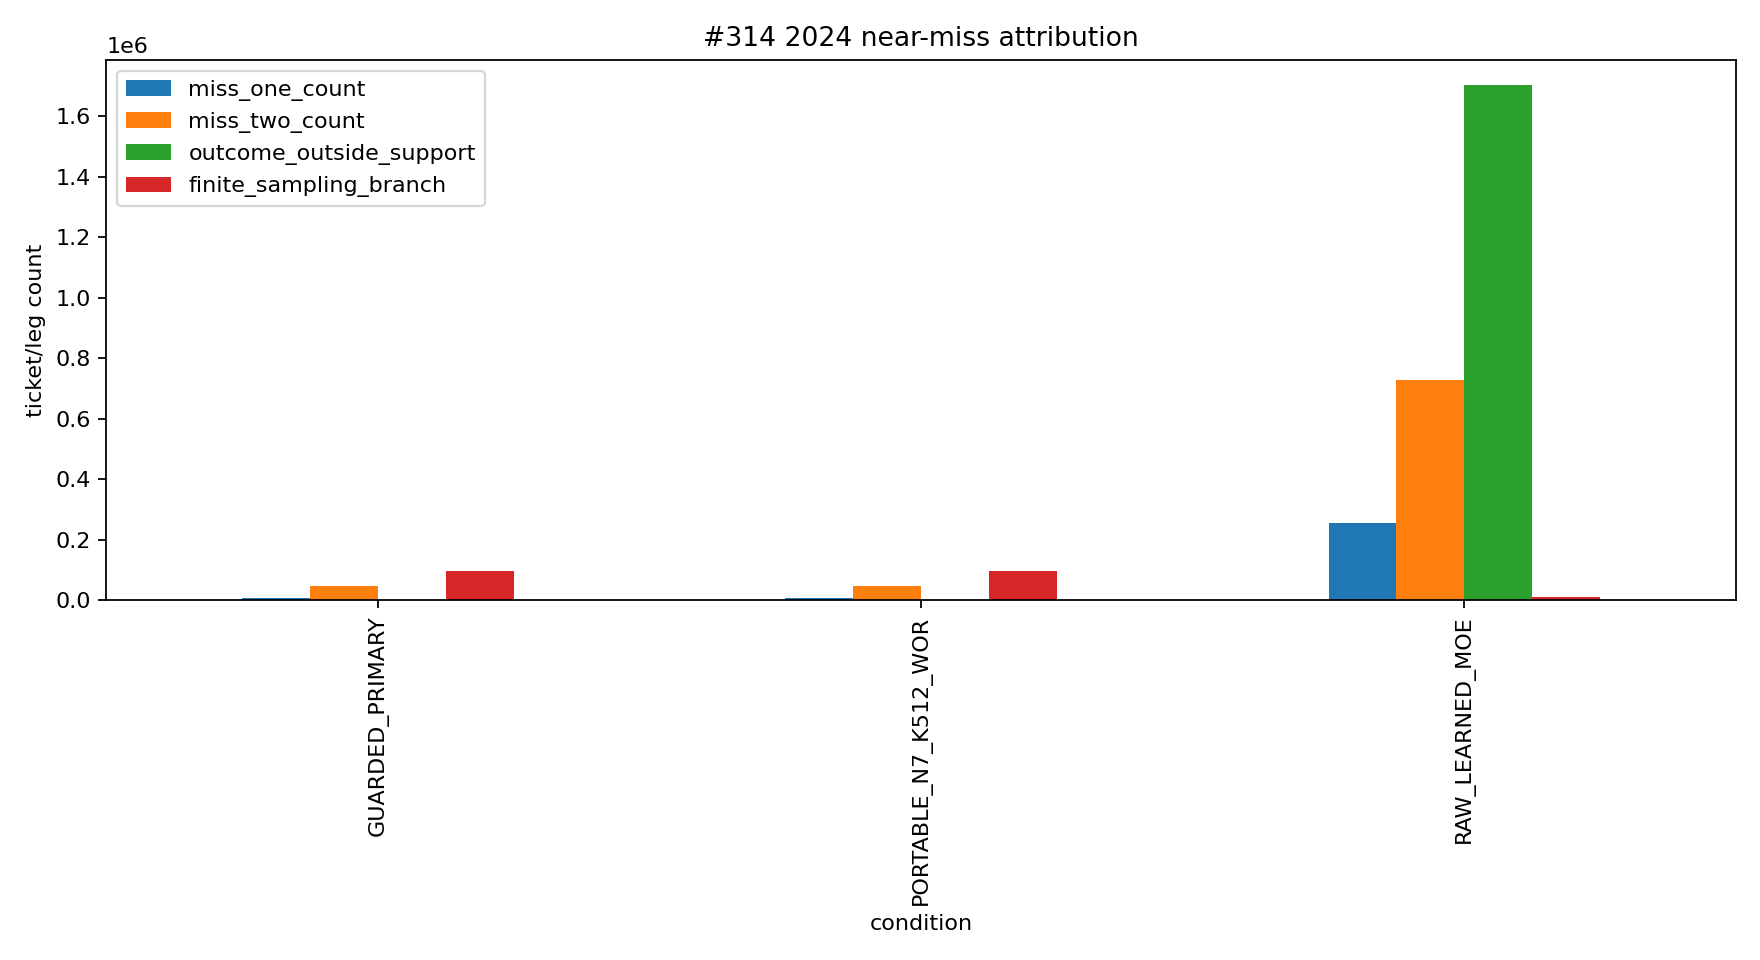

In [6]:
near = pd.read_parquet(OUTPUT / 'terminal_near_miss_2024.parquet')
display(near.groupby('condition', as_index=False).agg(
    miss_one=('miss_one_count','sum'), miss_two=('miss_two_count','sum'),
    outside_support=('outcome_outside_support','sum'),
    finite_sampling=('finite_sampling_branch','sum'),
    added_stake=('one_more_protection_stake_cny','sum'),
    added_pnl=('one_more_protection_pnl_cny','sum')))
display(Image(filename=str(OUTPUT / 'near_miss_attribution_2024.png')))

## Decision reading

The exact #312 control is retained for the 2023 validation anchor. Because its
fitted ticket identities do not exist for 2024, the terminal control is named
`PORTABLE_N7_K512_WOR` and is not represented as a byte-identical continuation.
Only a learned policy that passed 2023 could become promotable; a lucky 2024
raw challenger cannot retroactively pass the guard.